# Smart Snake: training convergence & agent comparison

This notebook reads the files produced by `train.py` and `test.py`:

| File | Produced by | Content |
|---|---|---|
| `logs/<run>/episodes.csv` | `train.py` | total (undiscounted) reward of every training episode |
| `logs/<run>/eval/evaluations.npz` | `train.py` (EvalCallback) | periodic deterministic evaluations |
| `results/eval_episodes.csv` | `test.py` | per-episode results of each agent |
| `results/eval_summary.csv` | `test.py` | aggregated metrics per agent |

Figures are also saved to `results/figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RUN = 'ppo_snake'
WINDOW = 100  # sliding window for the average episode reward
LOG_DIR = Path('logs') / RUN
RES_DIR = Path('results')
FIG_DIR = RES_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.precision', 3)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Training convergence

Convergence is assessed on the **total (undiscounted) reward per episode**. Because single-episode returns fluctuate a lot (random obstacle layouts, apple positions), we also plot a sliding-window average over the last `WINDOW` episodes.

In [2]:
train = pd.read_csv(LOG_DIR / 'episodes.csv')
train['avg_reward'] = train.total_reward.rolling(WINDOW, min_periods=1).mean()
train['avg_score'] = train.score.rolling(WINDOW, min_periods=1).mean()
print(f'{len(train)} training episodes, {train.timestep.iloc[-1]:,} timesteps')
train.tail()

22634 training episodes, 3,002,232 timesteps


,episode,timestep,total_reward,avg_reward_100,score,length,steps,death_cause,avg_reward,avg_score
22629,22630,3001720,261.85,150.432,26,28,275,self,150.432,15.59
22630,22631,3002048,143.03,149.759,15,17,127,self,149.759,15.53
22631,22632,3002120,85.83,150.404,9,12,87,obstacle,150.404,15.59
22632,22633,3002176,96.09,149.156,10,13,151,self,149.156,15.47
22633,22634,3002232,214.11,150.290,23,23,199,obstacle,150.290,15.59


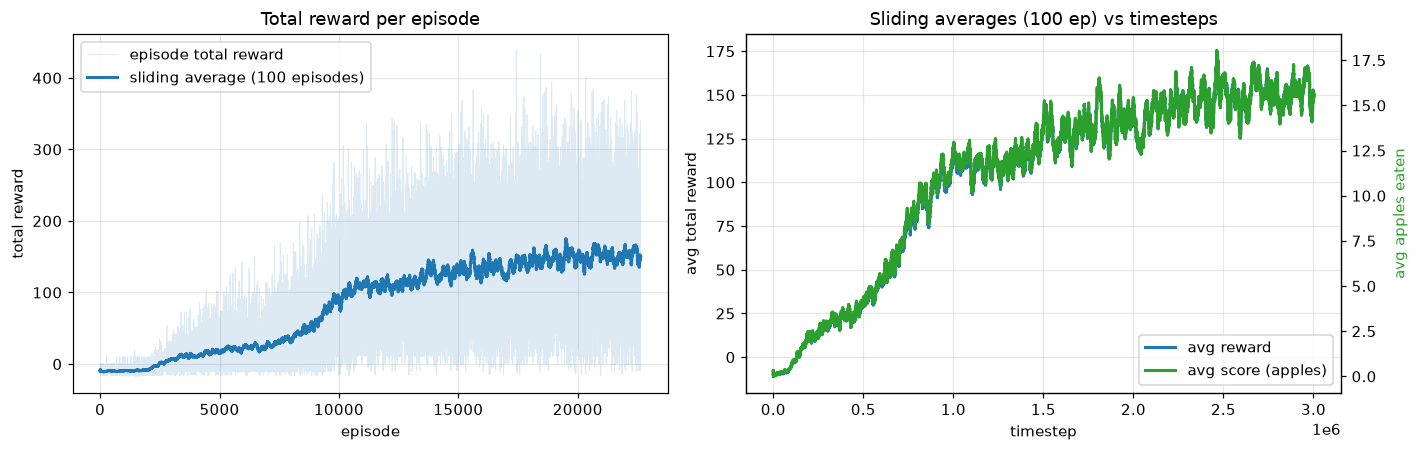

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
ax.plot(train.episode, train.total_reward, color='tab:blue', alpha=0.15, lw=0.6, label='episode total reward')
ax.plot(train.episode, train.avg_reward, color='tab:blue', lw=2, label=f'sliding average ({WINDOW} episodes)')
ax.set(xlabel='episode', ylabel='total reward', title='Total reward per episode')
ax.legend()
ax = axes[1]
ax.plot(train.timestep, train.avg_reward, color='tab:blue', lw=2, label='avg reward')
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(train.timestep, train.avg_score, color='tab:green', lw=2, label='avg score (apples)')
ax.set(xlabel='timestep', ylabel='avg total reward', title=f'Sliding averages ({WINDOW} ep) vs timesteps')
ax2.set_ylabel('avg apples eaten', color='tab:green')
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='lower right')
fig.tight_layout(); fig.savefig(FIG_DIR / 'training_convergence.png'); plt.show()

**Convergence check:** we compare the sliding average over successive tenths of training. Training is considered converged when the relative improvement between the last two blocks is small.

In [4]:
blocks = [train.iloc[idx] for idx in np.array_split(np.arange(len(train)), 10)]
conv = pd.DataFrame({
    'block': range(1, 11),
    'timesteps_end': [b.timestep.iloc[-1] for b in blocks],
    'mean_reward': [b.total_reward.mean() for b in blocks],
    'std_reward': [b.total_reward.std() for b in blocks],
    'mean_score': [b.score.mean() for b in blocks],
})
conv['rel_change_%'] = conv.mean_reward.pct_change() * 100
conv

,block,timesteps_end,mean_reward,std_reward,mean_score,rel_change_%
0,1,110384,-8.895,5.191,0.216,NaN
1,2,266432,8.697,15.991,1.930,-197.779
2,3,441480,21.080,23.929,3.137,142.378
3,4,688800,38.335,36.965,4.867,81.856
4,5,1109136,93.297,57.980,10.305,143.374
5,6,1477112,112.100,63.039,12.020,20.153
6,7,1850288,130.297,69.120,13.737,16.234
7,8,2224664,135.958,74.097,14.241,4.344
8,9,2610240,147.383,77.681,15.313,8.404
9,10,3002232,151.435,78.936,15.697,2.749


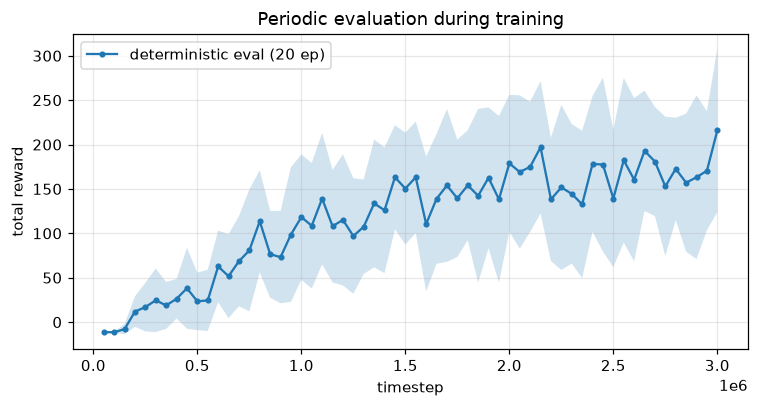

In [5]:
ev_file = LOG_DIR / 'eval' / 'evaluations.npz'
if ev_file.exists():
    ev = np.load(ev_file)
    m, s = ev['results'].mean(1), ev['results'].std(1)
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.plot(ev['timesteps'], m, marker='o', ms=3, label='deterministic eval (20 ep)')
    ax.fill_between(ev['timesteps'], m - s, m + s, alpha=0.2)
    ax.set(xlabel='timestep', ylabel='total reward', title='Periodic evaluation during training')
    ax.legend(); fig.tight_layout(); fig.savefig(FIG_DIR / 'periodic_eval.png'); plt.show()

## 2. RL agent vs rule-based agent

All agents play the **same seeded episodes** (seeds never used in training). Metrics and why we use them:

| Metric | Why |
|---|---|
| **Score (apples) mean / median / max, 95% CI** | the game objective itself; independent of reward shaping, so comparable for any agent |
| **Total reward** | the quantity the RL agent actually optimises (MDP objective, undiscounted) |
| **Steps per apple** | efficiency: how directly the agent reaches food |
| **Success rate (score >= 10)** | robustness: fraction of episodes that are not early failures |
| **Death-cause distribution** | *how* each agent fails (walls/obstacles vs self-trapping vs starvation) |
| **Poison eaten per episode** | hazard avoidance of the moving poison apple |
| **Decision time (ms)** | computational cost per action (deployment cost) |

In [6]:
episodes = pd.read_csv(RES_DIR / 'eval_episodes.csv')
summary = pd.read_csv(RES_DIR / 'eval_summary.csv')
main_cols = ['agent', 'episodes', 'score_mean', 'score_ci95', 'score_median', 'score_max',
             'total_reward_mean', 'steps_mean', 'steps_per_apple', 'success_rate_score>=10',
             'poison_per_episode', 'win_rate', 'decision_ms']
summary[main_cols].set_index('agent').T

agent,ppo,rule_based,random
episodes,200.000,200.000,200.000
score_mean,18.615,84.360,0.130
score_ci95,1.177,6.057,0.053
score_median,19.000,89.000,0.000
score_max,40.000,158.000,2.000
total_reward_mean,182.054,838.135,-9.308
steps_mean,193.940,1970.070,17.815
steps_per_apple,10.418,23.353,137.038
success_rate_score>=10,0.850,0.960,0.000
poison_per_episode,1.090,6.130,0.060


In [7]:
death_cols = [c for c in summary.columns if c.startswith('death_')]
deaths = summary.set_index('agent')[death_cols]
deaths.columns = [c.replace('death_', '').replace('_rate', '') for c in death_cols]
deaths.style.format('{:.1%}')

,wall,obstacle,self,poison,starvation,truncated
agent,,,,,,
ppo,5.5%,22.0%,70.5%,0.0%,2.0%,0.0%
rule_based,3.5%,2.0%,15.0%,0.0%,77.5%,2.0%
random,45.0%,53.5%,1.0%,0.5%,0.0%,0.0%


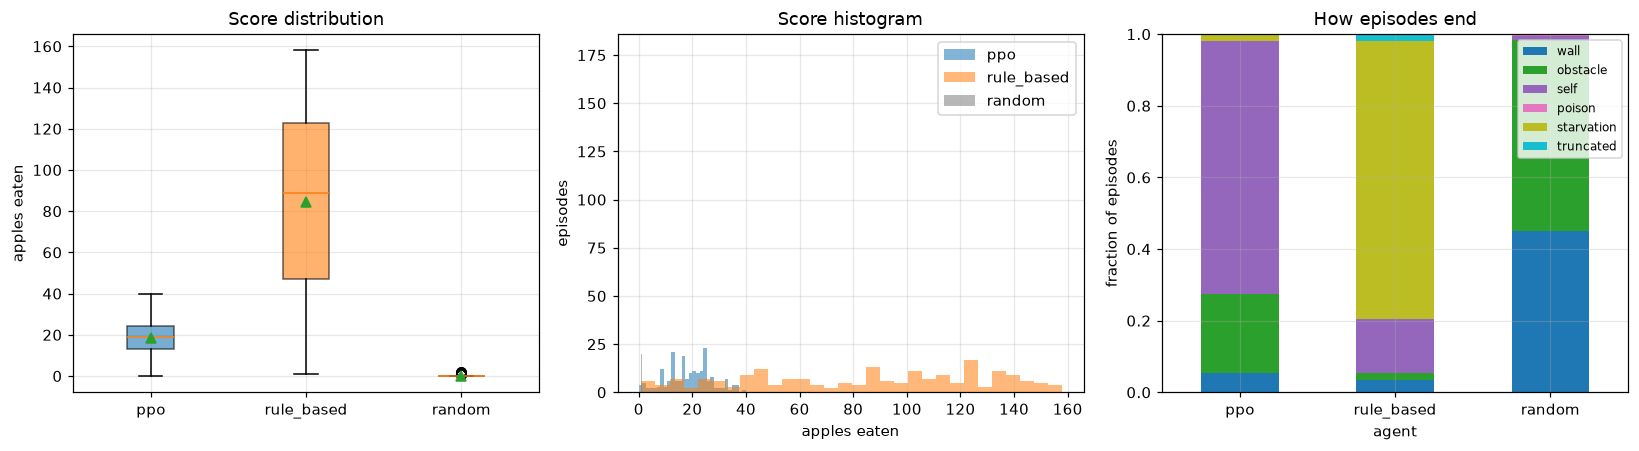

In [8]:
agents = list(summary.agent)
colors = {'ppo': 'tab:blue', 'rule_based': 'tab:orange', 'random': 'tab:gray'}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
data = [episodes.loc[episodes.agent == a, 'score'] for a in agents]
bp = axes[0].boxplot(data, tick_labels=agents, patch_artist=True, showmeans=True)
for patch, a in zip(bp['boxes'], agents):
    patch.set_facecolor(colors.get(a, 'tab:purple')); patch.set_alpha(0.6)
axes[0].set(title='Score distribution', ylabel='apples eaten')
for a in agents:
    d = episodes.loc[episodes.agent == a, 'score']
    axes[1].hist(d, bins=30, alpha=0.55, label=a, color=colors.get(a))
axes[1].set(title='Score histogram', xlabel='apples eaten', ylabel='episodes'); axes[1].legend()
deaths.plot.bar(stacked=True, ax=axes[2], colormap='tab10', rot=0)
axes[2].set(title='How episodes end', ylabel='fraction of episodes'); axes[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR / 'agent_comparison.png'); plt.show()

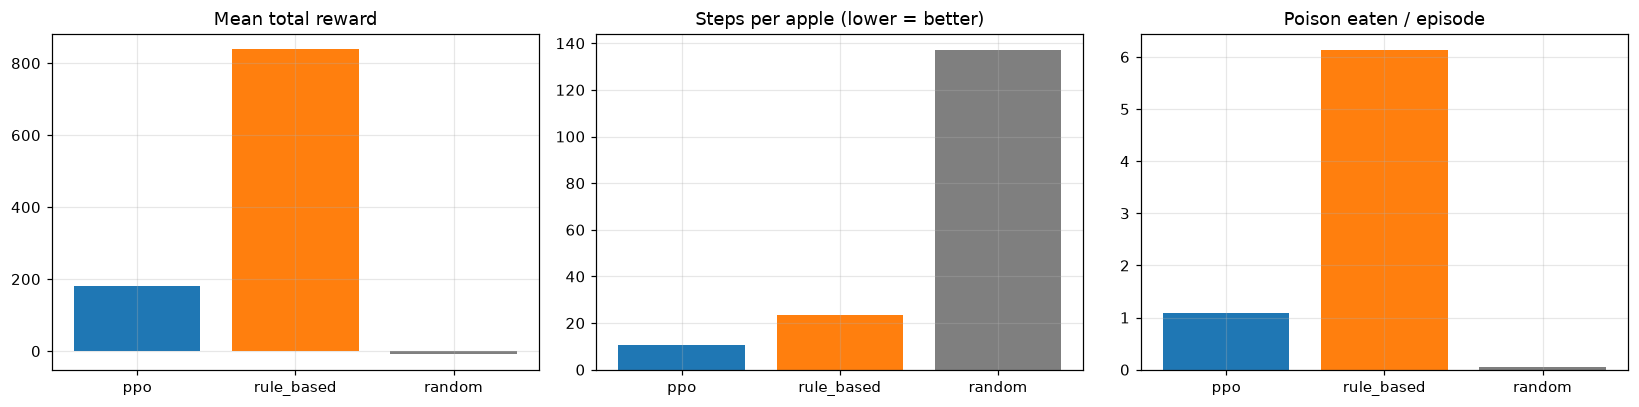

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (col, title) in zip(axes, [('total_reward_mean', 'Mean total reward'),
                                   ('steps_per_apple', 'Steps per apple (lower = better)'),
                                   ('poison_per_episode', 'Poison eaten / episode')]):
    ax.bar(summary.agent, summary[col], color=[colors.get(a) for a in summary.agent])
    ax.set_title(title)
fig.tight_layout(); fig.savefig(FIG_DIR / 'agent_metrics.png'); plt.show()

### Paired comparison on identical seeds
Each point is one seed played by both agents.

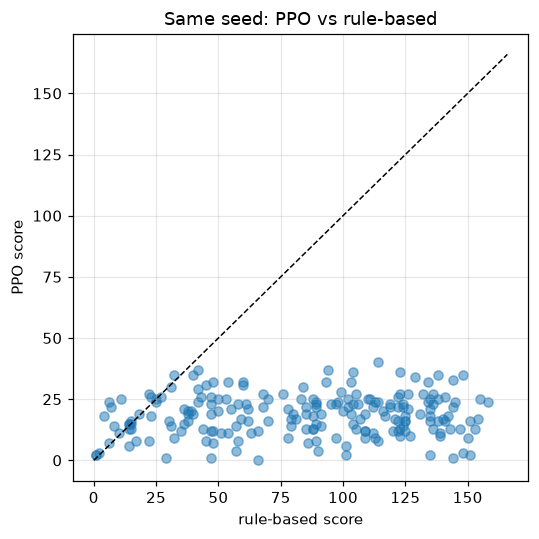

PPO better on 8.5% of seeds, tie 1.0%


In [10]:
if {'ppo', 'rule_based'} <= set(agents):
    pv = episodes.pivot(index='seed', columns='agent', values='score')
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.scatter(pv.rule_based, pv.ppo, alpha=0.5)
    lim = max(pv.max()) * 1.05
    ax.plot([0, lim], [0, lim], 'k--', lw=1)
    ax.set(xlabel='rule-based score', ylabel='PPO score', title='Same seed: PPO vs rule-based')
    fig.tight_layout(); fig.savefig(FIG_DIR / 'paired_scores.png'); plt.show()
    print(f"PPO better on {(pv.ppo > pv.rule_based).mean():.1%} of seeds, tie {(pv.ppo == pv.rule_based).mean():.1%}")